# BAFAD Week 5 — Exercise 1: 1D Convolutional Autoencoder

**Name:** Jaylin  
**Week:** 5 · Oct 26–Nov 1, 2026  
**Commit message:** `feat: train 1D conv autoencoder on clean sensor streams`  
**Objective:** Build and train a 1D convolutional autoencoder on clean SKAB sensor streams;
evaluate reconstruction error on contaminated versions; confirm that anomalous windows
produce higher reconstruction error than clean windows.

---

## Section 1: Setup & Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import tensorflow as tf
from tensorflow import keras

import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
tf.get_logger().setLevel('ERROR')

print(f'NumPy      version: {np.__version__}')
print(f'pandas     version: {pd.__version__}')
print(f'TensorFlow version: {tf.__version__}')
print('Imports successful.')

NumPy      version: 2.1.3
pandas     version: 2.2.3
TensorFlow version: 2.21.0
Imports successful.


## Section 2: Carry-Forward Functions from Weeks 3–4

Run this cell as-is.

In [2]:
def extract_anomaly_windows(anomaly_labels):
    """Converts binary label array to list of (start, end) tuples."""
    windows   = []
    in_window = False
    start     = 0
    for i, label in enumerate(anomaly_labels):
        if label == 1 and not in_window:
            start     = i
            in_window = True
        elif label == 0 and in_window:
            windows.append((start, i))
            in_window = False
    if in_window:
        windows.append((start, len(anomaly_labels)))
    return windows


def inject_noise_profile(raw_data, start_idx, end_idx, variance=2.5, mode='noise'):
    """Injects noise or blackout into a localized index window."""
    poisoned_data = raw_data.copy()
    window_rows   = end_idx - start_idx
    n_features    = poisoned_data.shape[1]
    if mode == 'noise':
        injection = np.random.normal(0, variance, size=(window_rows, n_features))
        poisoned_data[start_idx:end_idx, :] += injection
    elif mode == 'blackout':
        poisoned_data[start_idx:end_idx, :] = 0.0
    else:
        raise ValueError(f"Unknown mode: '{mode}'.")
    return poisoned_data


print('Carry-forward functions loaded.')

Carry-forward functions loaded.


## Section 3: Generate Synthetic SKAB-Format Dataset

Same spec as Week 4. Run this cell as-is.

In [3]:
def make_synthetic_skab_file(filepath, n_rows, anomaly_windows, seed=0):
    np.random.seed(seed)
    t       = np.linspace(0, 50, n_rows)
    sensors = {}
    names   = ['Accelerometer1RMS', 'Accelerometer2RMS', 'Current',
                'Pressure', 'Temperature', 'Thermocouple',
                'Voltage', 'Volume Flow RateRMS']
    for i, name in enumerate(names):
        sensors[name] = np.sin(t * (i + 1)) + np.random.normal(0, 0.05, n_rows)
    labels      = np.zeros(n_rows, dtype=int)
    changepoint = np.zeros(n_rows, dtype=int)
    for s, e in anomaly_windows:
        labels[s:e]    = 1
        changepoint[s] = 1
    idx = pd.date_range('2020-01-01', periods=n_rows, freq='1s')
    df  = pd.DataFrame(sensors, index=idx)
    df.index.name = 'datetime'
    df['anomaly']     = labels
    df['changepoint'] = changepoint
    df.to_csv(filepath, sep=';')


synth_dir = Path('synthetic_alldata')
synth_dir.mkdir(exist_ok=True)

files_spec = [
    ('1.csv', 800,  [(150, 230), (500, 580)]),
    ('2.csv', 1000, [(200, 350)]),
    ('3.csv', 600,  []),
    ('4.csv', 900,  [(100, 160), (400, 480), (700, 750)]),
    ('5.csv', 750,  [(300, 420)]),
]

for fname, n_rows, windows in files_spec:
    make_synthetic_skab_file(synth_dir / fname, n_rows, windows)

print('Synthetic SKAB dataset ready.')
for fname, n_rows, windows in files_spec:
    print(f'  {fname}: {n_rows} rows, {len(windows)} anomaly window(s)')

Synthetic SKAB dataset ready.
  1.csv: 800 rows, 2 anomaly window(s)
  2.csv: 1000 rows, 1 anomaly window(s)
  3.csv: 600 rows, 0 anomaly window(s)
  4.csv: 900 rows, 3 anomaly window(s)
  5.csv: 750 rows, 1 anomaly window(s)


## Section 4: Implement `make_windows()`

Converts a `(T, F)` sensor array into a `(N, window_size, F)` tensor of overlapping windows.

**Your task:** Complete the function body.

In [7]:
def make_windows(X, window_size=32, step=4):
    """
    Extracts overlapping sliding windows from a (T, F) sensor array.

    Parameters
    ----------
    X           : np.ndarray, shape (T, F)
    window_size : int — timesteps per window
    step        : int — stride between consecutive windows

    Returns
    -------
    windows : np.ndarray, shape (N, window_size, F)
    indices : np.ndarray of int — start index of each window in X
    """

    T = X.shape[0]
    starts = np.arange(0, T - window_size + 1, step)
    windows = np.stack([X[s:s + window_size] for s in starts])
    return windows, starts


# Shape check — must pass before continuing
dummy = np.random.randn(600, 8)
W, idx = make_windows(dummy, window_size=32, step=4)
expected_N = (600 - 32) // 4 + 1   # = 143
assert W.shape == (expected_N, 32, 8), f'Expected ({expected_N}, 32, 8), got {W.shape}'
assert len(idx) == expected_N
print(f'make_windows shape check passed: {W.shape}')

make_windows shape check passed: (143, 32, 8)


## Section 5: Implement `build_autoencoder()`

Build the 1D convolutional encoder → bottleneck → decoder using the Keras functional API.

**Your task:** Fill in the TODO items. Use the architecture table from the Resource Guide.

In [8]:
def build_autoencoder(window_size=32, n_features=8):
    """
    Builds and compiles a 1D convolutional autoencoder.

    Architecture
    ------------
    Input  (window_size, n_features)
    Encoder: Conv1D(16,3,relu,same) → MaxPool(2) → Conv1D(8,3,relu,same) → MaxPool(2)
    Decoder: Conv1D(8,3,relu,same) → UpSample(2) → Conv1D(16,3,relu,same) → UpSample(2)
             → Conv1D(n_features,3,linear,same)
    Output (window_size, n_features)

    Returns
    -------
    model : compiled keras.Model
    """
    inp = keras.Input(shape=(window_size, n_features))

    # Encoder
    x = keras.layers.Conv1D(16, 3, activation='relu', padding='same')(inp)
    x = keras.layers.MaxPooling1D(2)(x)
    x = keras.layers.Conv1D(8, 3, activation='relu', padding='same')(x)
    x = keras.layers.MaxPooling1D(2)(x)

    # Decoder
    x = keras.layers.Conv1D(8, 3, activation='relu', padding='same')(x)
    x = keras.layers.UpSampling1D(2)(x)
    x = keras.layers.Conv1D(16, 3, activation='relu', padding='same')(x)
    x = keras.layers.UpSampling1D(2)(x)
    out = keras.layers.Conv1D(n_features, 3, activation='linear', padding='same')(x)


    model = keras.Model(inp, out)
    model.compile(optimizer='adam', loss='mse')
    return model


# Shape check: output must match input
model = build_autoencoder(window_size=32, n_features=8)
test_in  = np.random.randn(4, 32, 8).astype(np.float32)
test_out = model.predict(test_in, verbose=0)
assert test_out.shape == test_in.shape, f'Shape mismatch: {test_out.shape}'
print(f'build_autoencoder shape check passed: {test_out.shape}')
model.summary()

build_autoencoder shape check passed: (4, 32, 8)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 32, 16)         │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 16, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 16, 8)          │           392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 8, 8)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 8, 8)           │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d (UpSampling1D)    │ (None, 16, 8)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 16, 16)         │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling1d_1 (UpSampling1D)  │ (None, 32, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 32, 8)          │           392 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,784 (6.97 KB)

 Trainable params: 1,784 (6.97 KB)

 Non-trainable params: 0 (0.00 B)

## Section 6: Prepare Training Data and Train

Run this cell as-is after your functions in Sections 4 and 5 pass their checks.

In [9]:
DATA_DIR = Path('synthetic_alldata')   # swap to Path('SKAB/alldata') for real data

SENSOR_COLS = ['Accelerometer1RMS', 'Accelerometer2RMS', 'Current',
               'Pressure', 'Temperature', 'Thermocouple',
               'Voltage', 'Volume Flow RateRMS']
WINDOW_SIZE = 32
STEP        = 4

# Load 3.csv (clean file) as training data
df_clean = pd.read_csv(DATA_DIR / '3.csv', sep=';', index_col='datetime', parse_dates=True)
X_clean  = df_clean[SENSOR_COLS].values.astype(np.float32)

X_train, _ = make_windows(X_clean, WINDOW_SIZE, STEP)
print(f'Training windows: {X_train.shape}  (N, W, F)')

tf.random.set_seed(42)
np.random.seed(42)

model = build_autoencoder(window_size=WINDOW_SIZE, n_features=X_train.shape[2])

history = model.fit(
    X_train, X_train,
    epochs=15,
    batch_size=16,
    validation_split=0.1,
    verbose=1
)

train_loss = history.history['loss']
print(f'\nInitial loss : {train_loss[0]:.6f}')
print(f'Final   loss : {train_loss[-1]:.6f}')
assert train_loss[-1] < train_loss[0], 'Training loss did not decrease!'
print('Training loss decreased — model is learning.')

model.save('autoencoder_week05.keras')
print('Model saved to autoencoder_week05.keras')

Training windows: (143, 32, 8)  (N, W, F)
Epoch 1/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.5268 - val_loss: 0.4884
Epoch 2/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.4792 - val_loss: 0.4594
Epoch 3/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.4538 - val_loss: 0.4335
Epoch 4/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.4295 - val_loss: 0.4046
Epoch 5/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.4016 - val_loss: 0.3725
Epoch 6/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.3723 - val_loss: 0.3423
Epoch 7/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.3437 - val_loss: 0.3157
Epoch 8/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.3178 - val_loss: 0.2928
Epoch 9/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.2949 - val_loss: 0.2727
Epoch 10/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2741 - val_loss: 0.2545
Epoch 11/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 0.2544 - val_loss: 0.2384
Epoch 12/15
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11m

## Section 7: Implement `reconstruction_error()` and Evaluate on 4.csv

**Your task:** Complete `reconstruction_error()`. The rest of the cell runs as-is after it.

In [10]:
def reconstruction_error(model, X, window_size=32, step=4):
    """
    Computes per-window MSE reconstruction error for a sensor array.

    Parameters
    ----------
    model       : trained keras.Model
    X           : np.ndarray, shape (T, F)
    window_size : int
    step        : int

    Returns
    -------
    errors  : np.ndarray, shape (N,) — MSE per window
    indices : np.ndarray of int — start index of each window
    """

    windows, indices = make_windows(X, window_size, step)
    reconstructed = model.predict(windows.astype(np.float32), verbose=0)
    errors = np.mean((windows - reconstructed) ** 2, axis=(1, 2))
    return errors, indices



# Load 4.csv — 3 anomaly windows
df4 = pd.read_csv(DATA_DIR / '4.csv', sep=';', index_col='datetime', parse_dates=True)
X4_clean  = df4[SENSOR_COLS].values.astype(np.float32)
labels4   = df4['anomaly'].values.astype(int)
windows4  = extract_anomaly_windows(labels4)
print(f'4.csv anomaly windows: {windows4}')

# Contaminate 4.csv with noise
np.random.seed(42)
X4_cont = X4_clean.copy()
for s, e in windows4:
    X4_cont = inject_noise_profile(X4_cont, s, e, variance=2.5, mode='noise')

# Compute reconstruction errors
err_clean, idx_clean = reconstruction_error(model, X4_clean, WINDOW_SIZE, STEP)
err_cont,  idx_cont  = reconstruction_error(model, X4_cont,  WINDOW_SIZE, STEP)

print(f'\nClean        — mean error: {err_clean.mean():.6f}')
print(f'Contaminated — mean error: {err_cont.mean():.6f}')

# Key assertion: contaminated error must be higher
assert err_cont.mean() > err_clean.mean(), \
    f'Expected contaminated error ({err_cont.mean():.6f}) > clean ({err_clean.mean():.6f})'
print('Assertion passed: contaminated mean error > clean mean error.')

4.csv anomaly windows: [(100, 160), (400, 480), (700, 750)]

Clean        — mean error: 0.225803
Contaminated — mean error: 1.674599
Assertion passed: contaminated mean error > clean mean error.


## Section 8: Visualization — Reconstruction Error Over Time

**Your task:** Fill in the TODO items to complete the two-panel plot.

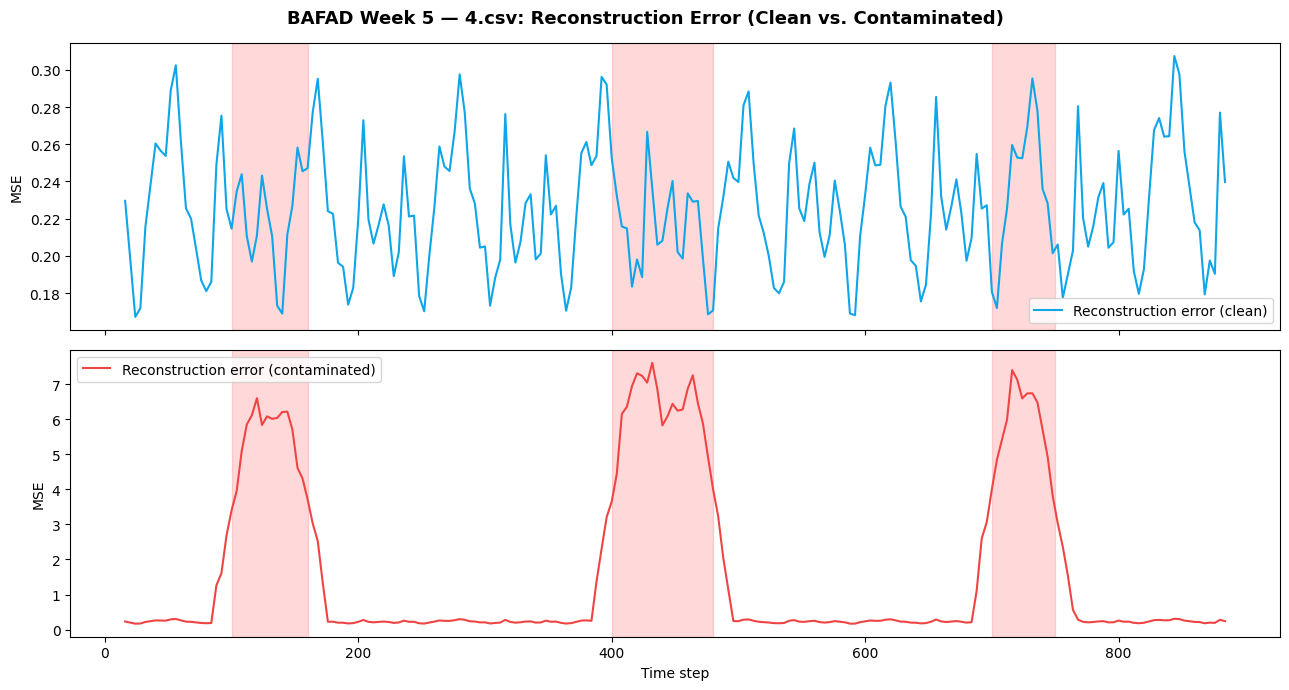

Plot saved to week05_exercise1_plot.png


In [11]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

# Map each window to its center timestep
center_clean = idx_clean + WINDOW_SIZE // 2
center_cont  = idx_cont  + WINDOW_SIZE // 2


# Plot clean reconstruction error
axes[0].plot(center_clean, err_clean, color='#0EA5E9',
             label='Reconstruction error (clean)')

# Plot contaminated reconstruction error
axes[1].plot(center_cont, err_cont, color='#EF4444',
             label='Reconstruction error (contaminated)')

# Shade anomaly windows on both graphs
for start, end in windows4:
    axes[0].axvspan(start, end, alpha=0.15, color='red')
    axes[1].axvspan(start, end, alpha=0.15, color='red')

# Add labels and legends
axes[0].set_ylabel('MSE')
axes[1].set_ylabel('MSE')
axes[1].set_xlabel('Time step')

axes[0].legend()
axes[1].legend()


fig.suptitle('BAFAD Week 5 — 4.csv: Reconstruction Error (Clean vs. Contaminated)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('week05_exercise1_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot saved to week05_exercise1_plot.png')

## Section 9: Interpretation Questions

Answer each question in 2–4 sentences.

**Q1.** Why is the autoencoder trained only on clean data? What would happen to
anomaly detection performance if contaminated windows were included in training?

> *[The autoencoder is trained on clean data because it needs to learn what normal sensor activity looks like. If contaminated data was included during training the model might start thinking those unusual patterns are normal. This would make it harder for the model to recognize anomalies when they happen.]*

**Q2.** `make_windows()` uses `step=4` and `window_size=32`. How many windows
are extracted from a 600-row file? Show your calculation.

> *[To figure out how many windows I get, I used the formula (600 - 32) // 4 + 1 = 143. So with 600 rows, a window size of 32, and a step of 4 I end up with 143 windows total.]*

**Q3.** A student plots reconstruction error and sees high error throughout the entire
file, not just in the anomaly windows. Name two possible causes and one diagnostic step for each.

> *[One reason could be that the model didn't learn the normal patterns well enough during training. I would check the training loss to see if it was actually improving. Another reason could be that the testing data is different from what the model was trained on. I would compare the sensor values and check if both datasets were processed the same way.]*

## Section 10: Git Commit

```bash
git add week05/BAFAD_Week05_Exercise1.ipynb
git add week05/autoencoder_week05.keras
git commit -m "feat: train 1D conv autoencoder on clean sensor streams"
git push origin main
```